<a href="https://colab.research.google.com/github/kanokwantho/Project_Tonper/blob/main/DataIP66_Q1_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import nbformat
from copy import deepcopy

# ชื่อไฟล์ต้นฉบับใน Google Drive
notebook_files = [
    ("Q1", "DataIP66Q1.ipynb"),
    ("Q2", "สำเนาของ Project_ton_ไตรมาส_2.ipynb"),
    ("Q3", "สำเนาของ quarter3.ipynb"),
    ("Q4", "สำเนาของ 66q4.ipynb"),
]

drive_root = "/content/drive/MyDrive"

# ค้นหาไฟล์ตามชื่อ
found_files = {}
for root, dirs, files in os.walk(drive_root):
    for quarter, filename in notebook_files:
        if filename in files and quarter not in found_files:
            found_files[quarter] = os.path.join(root, filename)

# ตรวจสอบว่าเจอครบทั้ง 4 ไฟล์หรือไม่
missing = [
    filename for quarter, filename in notebook_files
    if quarter not in found_files
]

if missing:
    print("ยังหาไฟล์เหล่านี้ไม่พบ:")
    for filename in missing:
        print("-", filename)
    print("กรุณาตรวจสอบชื่อไฟล์และตำแหน่งใน Google Drive")
else:
    merged = nbformat.v4.new_notebook()
    merged.cells = []

    for quarter, filename in notebook_files:
        path = found_files[quarter]
        notebook = nbformat.read(path, as_version=4)

        # เพิ่มหัวข้อก่อนเนื้อหาของแต่ละไตรมาส
        merged.cells.append(
            nbformat.v4.new_markdown_cell(
                f"# ไตรมาส {quarter[-1]}"
            )
        )

        # คัดลอกเซลล์จากไฟล์ต้นฉบับ
        merged.cells.extend(deepcopy(notebook.cells))

    # บันทึกเป็นไฟล์ใหม่ ไม่ทับต้นฉบับ
    output_path = os.path.join(
        drive_root, "รวมข้อมูลทุกไตรมาส.ipynb"
    )

    nbformat.write(merged, output_path)

    print("รวม Notebook สำเร็จ!")
    print("บันทึกที่:", output_path)
    print("จำนวนเซลล์ทั้งหมด:", len(merged.cells))

รวม Notebook สำเร็จ!
บันทึกที่: /content/drive/MyDrive/รวมข้อมูลทุกไตรมาส.ipynb
จำนวนเซลล์ทั้งหมด: 156


/usr/local/lib/python3.13/dist-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


In [16]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ค้นหาไฟล์ CSV จากตำแหน่งใน Google Drive
drive_root = "/content/drive/MyDrive"
csv_files = []

for root, dirs, files in os.walk(drive_root):
    for file in files:
        if file.startswith("opendata_02_service_ip_66q") and file.endswith(".csv"):
            csv_files.append(os.path.join(root, file))

if not csv_files:
    print("ไม่พบไฟล์ CSV สำเร็จรูปใน Drive กรุณาตรวจสอบตำแหน่งไฟล์")
else:
    print(f"พบไฟล์ CSV ทั้งหมด {len(csv_files)} ไฟล์ ดังนี้:")
    for f in csv_files:
        print("-", os.path.basename(f))

    # โหลดและรวมข้อมูล CSV ทุกไตรมาสเข้าด้วยกัน
    df_list = [pd.read_csv(f) for f in csv_files]
    combined_df = pd.concat(df_list, ignore_index=True)
    print(f"รวมไฟล์ CSV สำเร็จ! ได้จำนวนแถวทั้งหมด: {len(combined_df):,}")

# ใช้ข้อมูลที่รวม 4 ไตรมาสแล้ว
data = combined_df.copy()

# ตรวจสอบขนาดข้อมูล
print("\nจำนวนแถวและคอลัมน์:", data.shape)

# ตรวจสอบชื่อคอลัมน์
print("\nชื่อคอลัมน์ทั้งหมด:")
print(data.columns.tolist())

# ตรวจสอบข้อมูล 5 แถวแรก
display(data.head())

# ตรวจสอบชนิดข้อมูลและ Missing Values
print("\nชนิดข้อมูล:")
print(data.dtypes)

print("\nจำนวน Missing Values:")
print(data.isna().sum())

# เตรียมข้อมูลสำหรับการวิเคราะห์
text_cols = [
    "hname", "prov", "nhso_zonename",
    "service_type", "pdx", "pdx_name"
]

for col in text_cols:
    if col in data.columns:
        data[col] = (
            data[col].astype("string")
            .str.strip()
            .str.replace(r"\s+", " ", regex=True)
        )

if "n_service" in data.columns:
    data["n_service"] = pd.to_numeric(
        data["n_service"], errors="coerce"
    )

if "month_no" in data.columns:
    data["date"] = pd.to_datetime(
        data["month_no"].astype("string"),
        format="%Y%m",
        errors="coerce"
    )

print("\nเตรียมข้อมูลสำหรับวิเคราะห์เรียบร้อย")

พบไฟล์ CSV ทั้งหมด 4 ไฟล์ ดังนี้:
- opendata_02_service_ip_66q2.csv
- opendata_02_service_ip_66q1.csv
- opendata_02_service_ip_66q4.csv
- opendata_02_service_ip_66q3.csv


/tmp/ipykernel_3204/2799907292.py:24: DtypeWarning: Columns (1,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_list = [pd.read_csv(f) for f in csv_files]
/tmp/ipykernel_3204/2799907292.py:24: DtypeWarning: Columns (1,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_list = [pd.read_csv(f) for f in csv_files]
/tmp/ipykernel_3204/2799907292.py:24: DtypeWarning: Columns (1,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_list = [pd.read_csv(f) for f in csv_files]
/tmp/ipykernel_3204/2799907292.py:24: DtypeWarning: Columns (1,3) have mixed types. Specify dtype option on import or set low_memory=False.
  df_list = [pd.read_csv(f) for f in csv_files]


รวมไฟล์ CSV สำเร็จ! ได้จำนวนแถวทั้งหมด: 1,951,141

จำนวนแถวและคอลัมน์: (1951141, 12)

ชื่อคอลัมน์ทั้งหมด:
['month_no', 'hcode', 'hname', 'province_id', 'prov', 'nhso_zonename', 'gender', 'service_type', 'pdx', 'pdx_name', 'n_pop', 'n_service']


,month_no,hcode,hname,province_id,prov,nhso_zonename,gender,service_type,pdx,pdx_name,n_pop,n_service
0,202301,4007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,J18,Pneumonia organism unspecified,1,1
1,202301,4007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,2.0,IP,A09,Diarrhoea and gastroenteritis of presumed infe...,5,5
2,202301,4007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,L03,Cellulitis,2,2
3,202301,4007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,I63,Cerebral infarction,1,1
4,202301,4007,รพ.ซับใหญ่,3600,ชัยภูมิ,เขต 9 นครราชสีมา,1.0,IP,C76,Malignant neoplasm of other and ill-defined sites,1,1



ชนิดข้อมูล:
month_no           int64
hcode             object
hname             object
province_id       object
prov              object
nhso_zonename     object
gender           float64
service_type      object
pdx               object
pdx_name          object
n_pop              int64
n_service          int64
dtype: object

จำนวน Missing Values:
month_no            0
hcode               0
hname               0
province_id         0
prov                0
nhso_zonename       0
gender            112
service_type        0
pdx                 0
pdx_name         5042
n_pop               0
n_service           0
dtype: int64

เตรียมข้อมูลสำหรับวิเคราะห์เรียบร้อย


จำนวนครั้งเข้ารับบริการจำแนกตามภาค

In [20]:
# =========================================================
# 1. จัดกลุ่ม เขต สปสช. (nhso_zonename) เข้าสู่ภูมิภาคหลักก่อน
# =========================================================
zone_to_region = {
    'เขต 1 เชียงใหม่': 'ภาคเหนือ',
    'เขต 2 พิษณุโลก': 'ภาคเหนือ',
    'เขต 3 นครสวรรค์': 'ภาคเหนือ',
    'เขต 4 สระบุรี': 'ภาคกลาง',
    'เขต 5 ราชบุรี': 'ภาคตะวันตก',
    'เขต 6 ระยอง': 'ภาคตะวันออก',
    'เขต 7 ขอนแก่น': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 8 อุดรธานี': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 9 นครราชสีมา': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 10 อุบลราชธานี': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 11 สุราษฎร์ธานี': 'ภาคใต้',
    'เขต 12 สงขลา': 'ภาคใต้',
    'เขต 13 กรุงเทพมหานคร': 'กรุงเทพมหานคร',
    'กรมแพทย์ทหาร': 'หน่วยงานทหาร'
}

data['ภูมิภาค'] = data['nhso_zonename'].map(zone_to_region)

# =========================================================
# 2. ปรับกลุ่มกรมแพทย์ทหารและหน่วยงานพิเศษเข้าตามภูมิภาคจริง (ป้องกันไม่ให้ทับข้อมูลปกติ)
# =========================================================

# กรมแพทย์ทหารเรือ
data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('รพ.ทหารเรือกรุงเทพ|รพ.สมเด็จพระปิ่นเกล้า', na=False)),
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('ศูนย์ฝึกทหารใหม่|รร.ชุมพลฯ|กองพันพยาบาลกรมสนับสนุนหน่วยบัญชาการต่อสู้อากาศยาน|รพ.สมเด็จพระนางเจ้าสิริกิติ์', na=False)),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('จันทบุรีและตราด', na=False)),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

# กรมแพทย์ทหารอากาศ / หน่วยทหารอากาศ
data.loc[
    data['hname'].str.contains('รพ.ภูมิพลอดุลยเดช', na=False),
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    data['hname'].str.contains('รพ.จันทรุเบกษา', na=False),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

# โรงพยาบาลค่ายทหารบก หรือหน่วยพิเศษต่างๆ (เฉพาะจุดที่ยังเป็น หน่วยงานทหาร/NaN)
is_military_or_na = data['ภูมิภาค'].isin(['หน่วยงานทหาร', 'อื่นๆ']) | data['ภูมิภาค'].isna()

data.loc[
    data['hname'].str.contains('อานันทมหิดล|ค่ายธนะรัชต์|ค่ายจิรประวัติ|ค่ายอดิศร|ค่ายภาณุรังษี|ค่ายสุรสีห์', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    data['hname'].str.contains('ค่ายสุรนารี|ค่ายประจักษ์ศิลปาคม|ค่ายกฤษณ์สีวะรา|ค่ายสรรพสิทธิประสงค์|ค่ายวีรวัฒน์โยธิน', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคตะวันออกเฉียงเหนือ'

data.loc[
    data['hname'].str.contains('ค่ายสุรศักดิ์มนตรี|ค่ายสมเด็จพระนเรศวรมหาราช|ค่ายกาวิละ', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคเหนือ'

data.loc[
    data['hname'].str.contains('ค่ายวชิราวุธ|ค่ายเทพสตรีศรีสุนทร|ค่ายเสนาณรงค์|ค่ายอิงคยุทธบริหาร', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคใต้'

# หน่วยงานทหารที่เหลือทั้งหมด ปรับไปตามจังหวัดทางภูมิศาสตร์
data.loc[
    (data['ภูมิภาค'] == 'หน่วยงานทหาร') & (data['prov'] == 'กรุงเทพฯ'),
    'ภูมิภาค'
] = 'กรุงเทพมหานคร'

# เติมค่าว่างที่เหลือด้วยอื่นๆ
data['ภูมิภาค'] = data['ภูมิภาค'].fillna('อื่นๆ')

# =========================================================
# 3. ตรวจสอบผลลัพธ์หลังจัดกลุ่ม
# =========================================================

print("===== ตรวจสอบข้อมูลที่ยังไม่มีภูมิภาค =====")
missing_region = data[data['ภูมิภาค'] == 'อื่นๆ']
print("จำนวนข้อมูลที่เป็นอื่นๆ / ยังไม่มีภูมิภาค:", len(missing_region))

print("\n===== จำนวนข้อมูลในแต่ละภูมิภาคหลังปรับปรุง =====")
display(
    data['ภูมิภาค']
    .value_counts(dropna=False)
    .rename_axis('ภูมิภาค')
    .reset_index(name='count')
)

===== ตรวจสอบข้อมูลที่ยังไม่มีภูมิภาค =====
จำนวนข้อมูลที่เป็นอื่นๆ / ยังไม่มีภูมิภาค: 0

===== จำนวนข้อมูลในแต่ละภูมิภาคหลังปรับปรุง =====


,ภูมิภาค,count
0,ภาคตะวันออกเฉียงเหนือ,687349
1,ภาคเหนือ,411516
2,ภาคใต้,306269
3,ภาคตะวันออก,157746
4,ภาคตะวันตก,149508
5,ภาคกลาง,138830
6,กรุงเทพมหานคร,99923


In [28]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# =========================================================
# 1. จัดกลุ่ม เขต สปสช. (nhso_zonename) เข้าสู่ภูมิภาคหลักก่อน (รวมกรุงเทพฯ เข้าภาคกลาง)
# =========================================================
zone_to_region = {
    'เขต 1 เชียงใหม่': 'ภาคเหนือ',
    'เขต 2 พิษณุโลก': 'ภาคเหนือ',
    'เขต 3 นครสวรรค์': 'ภาคเหนือ',
    'เขต 4 สระบุรี': 'ภาคกลาง',
    'เขต 5 ราชบุรี': 'ภาคตะวันตก',
    'เขต 6 ระยอง': 'ภาคตะวันออก',
    'เขต 7 ขอนแก่น': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 8 อุดรธานี': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 9 นครราชสีมา': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 10 อุบลราชธานี': 'ภาคตะวันออกเฉียงเหนือ',
    'เขต 11 สุราษฎร์ธานี': 'ภาคใต้',
    'เขต 12 สงขลา': 'ภาคใต้',
    'เขต 13 กรุงเทพมหานคร': 'ภาคกลาง',  # <--- เปลี่ยนเป็นภาคกลาง
    'กรมแพทย์ทหาร': 'หน่วยงานทหาร'
}

data['ภูมิภาค'] = data['nhso_zonename'].map(zone_to_region)

# =========================================================
# 2. ปรับกลุ่มกรมแพทย์ทหารและหน่วยงานพิเศษเข้าตามภูมิภาคจริง
# =========================================================

# กรมแพทย์ทหารเรือ
data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('รพ.ทหารเรือกรุงเทพ|รพ.สมเด็จพระปิ่นเกล้า', na=False)),
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('ศูนย์ฝึกทหารใหม่|รร.ชุมพลฯ|กองพันพยาบาลกรมสนับสนุนหน่วยบัญชาการต่อสู้อากาศยาน|รพ.สมเด็จพระนางเจ้าสิริกิติ์', na=False)),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

data.loc[
    (data['prov'] == 'กรมแพทย์ทหารเรือ') &
    (data['hname'].str.contains('จันทบุรีและตราด', na=False)),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

# กรมแพทย์ทหารอากาศ / หน่วยทหารอากาศ
data.loc[
    data['hname'].str.contains('รพ.ภูมิพลอดุลยเดช', na=False),
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    data['hname'].str.contains('รพ.จันทรุเบกษา', na=False),
    'ภูมิภาค'
] = 'ภาคตะวันออก'

# โรงพยาบาลค่ายทหารบก หรือหน่วยพิเศษต่างๆ (เฉพาะจุดที่ยังเป็น หน่วยงานทหาร/NaN)
is_military_or_na = data['ภูมิภาค'].isin(['หน่วยงานทหาร', 'อื่นๆ']) | data['ภูมิภาค'].isna()

data.loc[
    data['hname'].str.contains('อานันทมหิดล|ค่ายธนะรัชต์|ค่ายจิรประวัติ|ค่ายอดิศร|ค่ายภาณุรังษี|ค่ายสุรสีห์', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคกลาง'

data.loc[
    data['hname'].str.contains('ค่ายสุรนารี|ค่ายประจักษ์ศิลปาคม|ค่ายกฤษณ์สีวะรา|ค่ายสรรพสิทธิประสงค์|ค่ายวีรวัฒน์โยธิน', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคตะวันออกเฉียงเหนือ'

data.loc[
    data['hname'].str.contains('ค่ายสุรศักดิ์มนตรี|ค่ายสมเด็จพระนเรศวรมหาราช|ค่ายกาวิละ', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคเหนือ'

data.loc[
    data['hname'].str.contains('ค่ายวชิราวุธ|ค่ายเทพสตรีศรีสุนทร|ค่ายเสนาณรงค์|ค่ายอิงคยุทธบริหาร', na=False) & is_military_or_na,
    'ภูมิภาค'
] = 'ภาคใต้'

# หน่วยงานทหารที่เหลือทั้งหมด ปรับไปตามจังหวัดทางภูมิศาสตร์ (กรุงเทพฯ ยุบเข้าภาคกลาง)
data.loc[
    (data['ภูมิภาค'] == 'หน่วยงานทหาร') & (data['prov'] == 'กรุงเทพฯ'),
    'ภูมิภาค'
] = 'ภาคกลาง'  # <--- เปลี่ยนเป็นภาคกลาง

# เติมค่าว่างที่เหลือด้วยอื่นๆ
data['ภูมิภาค'] = data['ภูมิภาค'].fillna('อื่นๆ')

# =========================================================
# 3. คำนวณจำนวนครั้งการรับบริการจำแนกตามภาคที่จัดกลุ่มแล้ว
# =========================================================
region_service = (
    data.groupby("ภูมิภาค")["n_service"]
    .sum()
    .sort_values(ascending=False)
)

region_table = region_service.rename(
    "จำนวนครั้งเข้ารับบริการ"
).reset_index()

region_table["ร้อยละ"] = (
    region_table["จำนวนครั้งเข้ารับบริการ"]
    / region_table["จำนวนครั้งเข้ารับบริการ"].sum() * 100
).round(2)

# แสดงตารางผลลัพธ์
display(region_table)

,ภูมิภาค,จำนวนครั้งเข้ารับบริการ,ร้อยละ
0,ภาคตะวันออกเฉียงเหนือ,2271693,37.95
1,ภาคเหนือ,1203505,20.10
2,ภาคใต้,929721,15.53
3,ภาคกลาง,674287,11.26
4,ภาคตะวันออก,461806,7.71
5,ภาคตะวันตก,445558,7.44


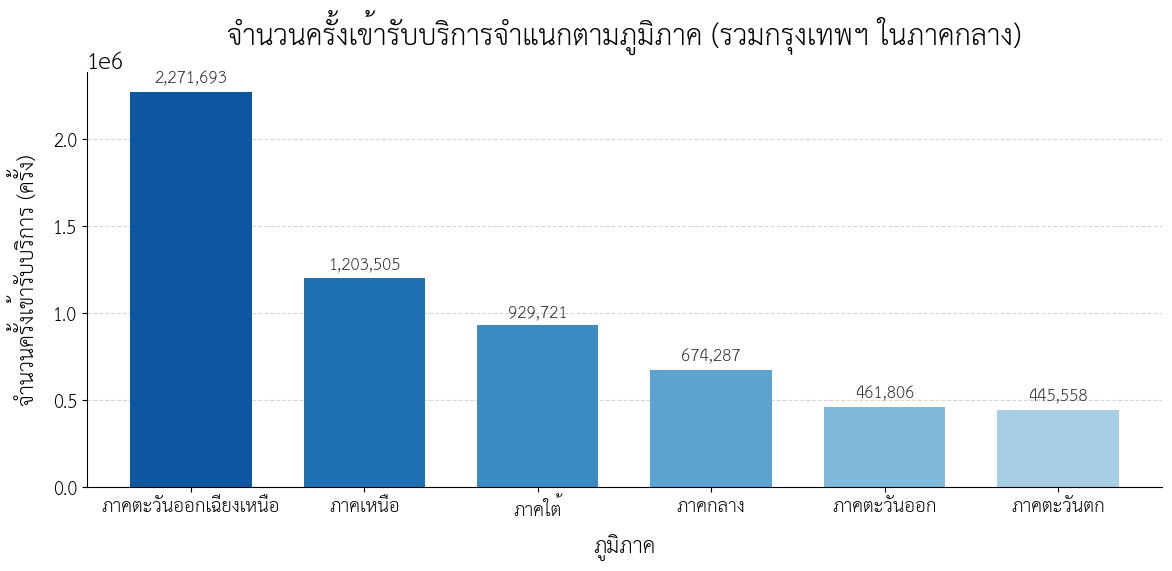

In [29]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# 4. ตั้งค่าฟอนต์ภาษาไทยและพล็อตกราฟแท่ง
mpl.font_manager.fontManager.addfont('thsarabunnew-webfont.ttf')
plt.rcParams['font.family'] = 'TH Sarabun New'
plt.rcParams['font.size'] = 16
plt.rcParams['axes.unicode_minus'] = False

# ขยายขนาดความกว้างเพื่อให้มีพื้นที่สำหรับข้อมูลภูมิภาค
fig, ax = plt.subplots(figsize=(12, 6))

# สร้างโทนสีฟ้าไล่ระดับ (Gradient) ให้เข้ากับธีมข้อมูลสุขภาพ/ราชการ
colors = plt.cm.Blues(np.linspace(0.85, 0.35, len(region_service)))

# พล็อตกราฟแท่ง
region_service.plot(kind="bar", color=colors, ax=ax, width=0.7)

# ตกแต่งหัวข้อและป้ายกำกับแกน (เปลี่ยนจาก เขตพื้นที่ เป็น ภูมิภาค)
plt.title("จำนวนครั้งเข้ารับบริการจำแนกตามภูมิภาค (รวมกรุงเทพฯ ในภาคกลาง)", fontsize=20, fontweight='bold', pad=20)
plt.xlabel("ภูมิภาค", fontsize=15, labelpad=10)
plt.ylabel("จำนวนครั้งเข้ารับบริการ (ครั้ง)", fontsize=15, labelpad=10)

# ตั้งค่าแกน X และ Y (ไม่ต้องเอียงเยอะเพราะชื่อภูมิภาคสั้นและอ่านง่ายกว่า)
plt.xticks(rotation=0, ha='center', fontsize=13)
plt.yticks(fontsize=13)

# เพิ่มเส้น Grid แนวนอนด้านหลัง เพื่อให้อ่านค่าได้ง่ายขึ้น
ax.yaxis.grid(True, linestyle='--', alpha=0.5, zorder=0)
ax.set_axisbelow(True)

# เอาเส้นขอบบนและขวาออก เพื่อความสะอาดตา (Modern Look)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# เพิ่มตัวเลขจำนวนครั้งบนหัวแท่งกราฟแต่ละแท่ง
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4),  # ระยะห่างจากหัวแท่งกราฟ
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=12, color='#333333')

plt.tight_layout()
plt.show()

In [30]:
# 1. เติมค่าว่างในชื่อโรคก่อนทำ Groupby (เพื่อป้องกันข้อมูลที่เป็น NaN หายไป)
data["pdx_name"] = data["pdx_name"].fillna("ไม่ระบุโรค")

# 2. จัดกลุ่มตามภูมิภาคและชื่อโรค พร้อมรวมจำนวนครั้งบริการ
region_disease = (
    data.groupby(["ภูมิภาค", "pdx_name"])["n_service"]
    .sum()
    .reset_index()
)

# 3. เรียงลำดับและดึง Top 5 ของแต่ละภูมิภาค
top5_region = (
    region_disease.sort_values(
        ["ภูมิภาค", "n_service"], ascending=[True, False]
    )
    .groupby("ภูมิภาค")
    .head(5)
)

display(top5_region)

,ภูมิภาค,pdx_name,n_service
1202,ภาคกลาง,Senile cataract,30575
1089,ภาคกลาง,Pneumonia organism unspecified,20138
277,ภาคกลาง,Diarrhoea and gastroenteritis of presumed infe...,19436
443,ภาคกลาง,Heart failure,16121
157,ภาคกลาง,Cerebral infarction,15490
1637,ภาคตะวันตก,Diarrhoea and gastroenteritis of presumed infe...,19421
2508,ภาคตะวันตก,Senile cataract,19114
2408,ภาคตะวันตก,Pneumonia organism unspecified,15214
1798,ภาคตะวันตก,Heart failure,11526
1405,ภาคตะวันตก,Acute bronchitis,10303


Top 5 โรคในแต่ละภาค

In [41]:
import pandas as pd
import plotly.express as px

# 1. เตรียมข้อมูลจากตัวแปร data ที่มีอยู่จริงในระบบ
df_plot = data[['ภูมิภาค', 'pdx_name', 'n_service']].copy()

# 2. ทำความสะอาดข้อมูล
df_plot['n_service'] = pd.to_numeric(
    df_plot['n_service'], errors='coerce'
)

df_plot = df_plot.dropna(
    subset=['ภูมิภาค', 'pdx_name', 'n_service']
)

# 3. หา Top 5 โรคที่มีจำนวนบริการสูงสุดในภาพรวม
top_diseases = (
    df_plot.groupby('pdx_name')['n_service']
    .sum()
    .nlargest(5)
    .index
)

# 4. กรองข้อมูลเฉพาะโรคที่เป็น Top 5 และรวมจำนวนบริการจำแนกตามภูมิภาค
df_area = df_plot[
    df_plot['pdx_name'].isin(top_diseases)
].groupby(
    ['ภูมิภาค', 'pdx_name'], as_index=False
)['n_service'].sum()

# 5. เรียงลำดับภูมิภาคเพื่อให้แสดงผลบนแกน X อย่างเป็นระบบ
region_order = [
    'ภาคเหนือ', 'ภาคตะวันออกเฉียงเหนือ', 'ภาคกลาง',
    'ภาคตะวันออก', 'ภาคตะวันตก', 'ภาคใต้', 'อื่นๆ'
]

# แปลงประเภทข้อมูลเป็นข้อความเพื่อป้องกันปัญหาการจัดลำดับ
df_area['ภูมิภาค'] = df_area['ภูมิภาค'].astype(str)

# กำหนดลำดับแกน X
order = [r for r in region_order if r in df_area['ภูมิภาค'].unique()]
order += [r for r in df_area['ภูมิภาค'].unique() if r not in order]

print("จำนวนแถวข้อมูลที่ใช้พล็อตกราฟ:", len(df_area))
print(df_area.head(10))

# 6. สร้างกราฟแท่งแบบกลุ่มด้วย Plotly (แก้ไข 'region' ให้กลับเป็น 'ภูมิภาค')
fig = px.bar(
    df_area,
    x='ภูมิภาค',
    y='n_service',
    color='pdx_name',
    barmode='group',
    category_orders={'ภูมิภาค': order},
    title='Top 5 โรคที่มีจำนวนการให้บริการสูงสุด จำแนกตามภูมิภาค',
    labels={
        'ภูมิภาค': 'ภูมิภาค',
        'n_service': 'จำนวนครั้งการให้บริการ',
        'pdx_name': 'โรค/อาการ'
    },
    color_discrete_sequence=px.colors.qualitative.Safe,
    template='plotly_white'
)

fig.update_layout(
    xaxis_title='ภูมิภาค',
    yaxis_title='จำนวนครั้งการให้บริการ (ครั้ง)',
    legend=dict(
        orientation='h',
        yanchor='top',
        y=-0.25,        # ย้ายคำอธิบายสี (Legend) ลงมาไว้ด้านล่างกราฟ
        xanchor='center',
        x=0.5
    ),
    margin=dict(t=100, b=120)  # เว้นขอบบนและขอบล่างให้พอดี ไม่ให้ตัวหนังสือเบียดกัน
)

จำนวนแถวข้อมูลที่ใช้พล็อตกราฟ: 30
      ภูมิภาค                                           pdx_name  n_service
0     ภาคกลาง                              Chronic renal failure      10124
1     ภาคกลาง  Diarrhoea and gastroenteritis of presumed infe...      19436
2     ภาคกลาง        Other chronic obstructive pulmonary disease       8531
3     ภาคกลาง                     Pneumonia organism unspecified      20138
4     ภาคกลาง                                    Senile cataract      30575
5  ภาคตะวันตก                              Chronic renal failure       7874
6  ภาคตะวันตก  Diarrhoea and gastroenteritis of presumed infe...      19421
7  ภาคตะวันตก        Other chronic obstructive pulmonary disease       8615
8  ภาคตะวันตก                     Pneumonia organism unspecified      15214
9  ภาคตะวันตก                                    Senile cataract      19114


สัดส่วนเพศของผู้เข้ารับบริการใน 5 โรคหลัก

In [44]:
import numpy as np
import pandas as pd
import plotly.express as px

# 1. แปลงค่าตัวเลขเพศ (gender) เป็นข้อความอธิบาย (gender_label)
gender_map = {1.0: 'ชาย', 2.0: 'หญิง'}
data['gender_label'] = data['gender'].map(gender_map).fillna('ไม่ระบุ')

# 2. หา Top 5 โรคที่มีการให้บริการสูงสุดในภาพรวม
top5_diseases = (
    data.groupby("pdx_name")["n_service"]
    .sum()
    .nlargest(5)
    .index
)

# 3. จัดกลุ่มตามโรคและเพศ (เตรียมข้อมูลแบบตารางยาวสำหรับ Plotly)
df_gender = (
    data[data["pdx_name"].isin(top5_diseases)]
    .groupby(["pdx_name", "gender_label"], as_index=False)["n_service"]
    .sum()
)

print("=== ข้อมูลสรุปจำแนกตามโรคและเพศ ===")
display(df_gender.head(10))

# 4. สร้างกราฟแท่งแนวนอนแบบกลุ่มด้วย Plotly (รองรับการ Hover ดูข้อมูลจริงทันที)
fig = px.bar(
    df_gender,
    y='pdx_name',           # ให้ชื่อโรคอยู่แกน Y เพื่อให้อ่านชื่อโรคง่าย ไม่ทับกัน
    x='n_service',          # จำนวนครั้งการให้บริการ
    color='gender_label',   # แยกสีตามเพศ
    barmode='group',        # จัดกลุ่มแท่งกราฟเทียบกัน
    title='สัดส่วนการให้บริการจำแนกตามเพศ ใน 5 โรคหลัก',
    labels={
        'pdx_name': 'กลุ่มโรค',
        'n_service': 'จำนวนครั้งการให้บริการ (ครั้ง)',
        'gender_label': 'เพศ'
    },
    color_discrete_map={'ชาย': '#3498db', 'หญิง': '#e74c3c', 'ไม่ระบุ': '#95a5a6'},
    template='plotly_white'
)

# 5. ปรับแต่งดีไซน์และการจัดวางเลย์เอาต์
fig.update_layout(
    yaxis={'categoryorder': 'total ascending'}, # เรียงลำดับโรคจากน้อยไปมาก ให้ค่าสูงสุดอยู่ด้านบนสุด
    xaxis_title='จำนวนครั้งการให้บริการ (ครั้ง)',
    yaxis_title='กลุ่มโรค',
    legend=dict(
        orientation='h',
        yanchor='bottom',
        y=1.12,             # วางคำอธิบายเพศไว้ด้านบนสวยๆ
        xanchor='center',
        x=0.5
    ),
    margin=dict(t=100, l=200) # เผื่อพื้นที่ด้านซ้ายสำหรับชื่อโรครักษาความยาว
)

fig.show()

=== ข้อมูลสรุปจำแนกตามโรคและเพศ ===


,pdx_name,gender_label,n_service
0,Chronic renal failure,ชาย,54295
1,Chronic renal failure,หญิง,71850
2,Chronic renal failure,ไม่ระบุ,5
3,Diarrhoea and gastroenteritis of presumed infe...,ชาย,131223
4,Diarrhoea and gastroenteritis of presumed infe...,หญิง,150394
5,Diarrhoea and gastroenteritis of presumed infe...,ไม่ระบุ,6
6,Other chronic obstructive pulmonary disease,ชาย,99185
7,Other chronic obstructive pulmonary disease,หญิง,26543
8,Other chronic obstructive pulmonary disease,ไม่ระบุ,9
9,Pneumonia organism unspecified,ชาย,124744


In [46]:
import pandas as pd
import plotly.express as px

# 1. จัดกลุ่มและคำนวณตามเขตสุขภาพ
zone_service = (
    data.groupby("nhso_zonename", dropna=False)["n_service"]
    .sum()
    .reset_index(name="จำนวนครั้งเข้ารับบริการ")
    .sort_values(by="จำนวนครั้งเข้ารับบริการ", ascending=True) # เรียงจากน้อยไปมาก เพื่อให้ค่ามากสุดอยู่ด้านบนสุดใน Plotly
)

# แปลงเป็นสตริงเพื่อความปลอดภัยในการแสดงผล
zone_service['nhso_zonename'] = zone_service['nhso_zonename'].astype(str)

display(zone_service.sort_values(by="จำนวนครั้งเข้ารับบริการ", ascending=False))

# 2. สร้างกราฟแท่งแนวนอนด้วย Plotly (รองรับ Hover แสดงข้อมูลจริง และไม่ทับกัน)
fig = px.bar(
    zone_service,
    x='จำนวนครั้งเข้ารับบริการ',
    y='nhso_zonename',
    orientation='h', # แนวนอน
    title='จำนวนครั้งเข้ารับบริการตามเขตสุขภาพ',
    labels={
        'nhso_zonename': 'เขตสุขภาพ',
        'จำนวนครั้งเข้ารับบริการ': 'จำนวนครั้งเข้ารับบริการ (ครั้ง)'
    },
    color='จำนวนครั้งเข้ารับบริการ',
    color_continuous_scale='Blues',
    template='plotly_white'
)

# 3. ตกแต่งเลย์เอาต์ให้สวยงาม
fig.update_layout(
    xaxis_title='จำนวนครั้งเข้ารับบริการ (ครั้ง)',
    yaxis_title='เขตสุขภาพ',
    yaxis={'categoryorder': 'total ascending'}, # เรียงลำดับเขตสุขภาพอัตโนมัติ
    margin=dict(t=80, l=150) # เว้นพื้นที่ด้านซ้ายสำหรับชื่อเขตที่ยาว
)

fig.show()

,nhso_zonename,จำนวนครั้งเข้ารับบริการ
13,เขต 9 นครราชสีมา,668986
1,เขต 1 เชียงใหม่,610907
12,เขต 8 อุดรธานี,571142
11,เขต 7 ขอนแก่น,542151
2,เขต 10 อุบลราชธานี,489414
4,เขต 12 สงขลา,481708
10,เขต 6 ระยอง,459997
3,เขต 11 สุราษฎร์ธานี,448013
9,เขต 5 ราชบุรี,446258
8,เขต 4 สระบุรี,368420


จำนวนครั้งเข้ารับบริการตามภาคและจังหวัด

In [63]:
import pandas as pd
import plotly.express as px

# จัดกลุ่มข้อมูลตาม ภูมิภาค และ จังหวัด
df_tree = data.groupby(['ภูมิภาค', 'prov'], as_index=False)['n_service'].sum()

fig = px.treemap(
    df_tree,
    path=['ภูมิภาค', 'prov'],           # ลำดับชั้น Hierarchy (ภูมิภาค -> จังหวัด)
    values='n_service',                 # ขนาดบล็อกตามจำนวนการบริการ
    color='n_service',                  # ความเข้มสีตามจำนวนบริการ
    color_continuous_scale='Blues',     # ชุดสีโทนฟ้า
    title='Treemap แสดงสัดส่วนการใช้บริการสุขภาพ (ภูมิภาค -> จังหวัด)'
)

# เพิ่มคำสั่งให้แสดงข้อมูล (ชื่อและตัวเลข) ลงบนบล็อกกราฟทันที
fig.update_traces(
    root_color="lightgrey",
    textinfo="label+value",
    textfont=dict(size=13)
)

fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))

fig.show()

สัดส่วนเพศจำแนกตามภูมิภาค

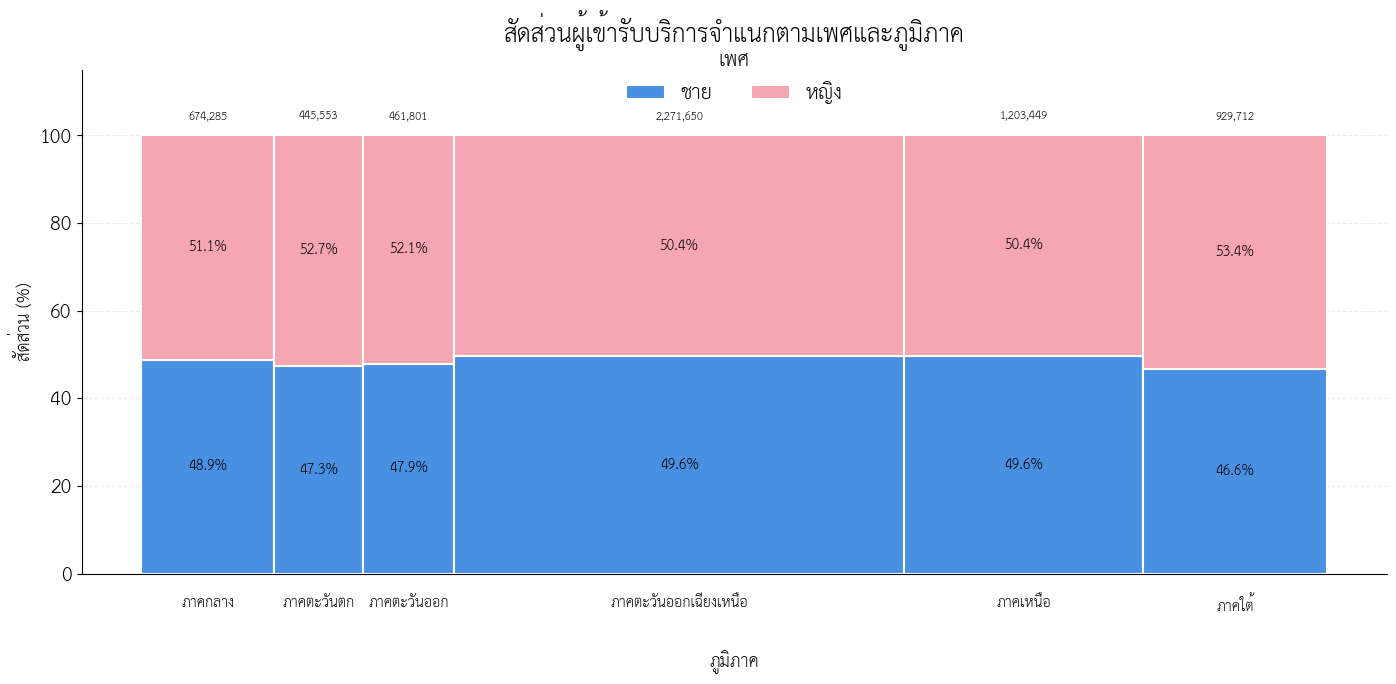

In [66]:
# ==========================================
# สัดส่วนผู้เข้ารับบริการจำแนกตามเพศและภูมิภาค (ความกว้างแท่งแปรผันตามสัดส่วนบริการ)
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

# -------------------------
# 1. แปลงรหัสเพศ
# -------------------------
data["gender_label"] = data["gender"].map({
    1: "ชาย",
    2: "หญิง"
}).fillna("ไม่ระบุ")


# -------------------------
# 2. รวมจำนวนบริการตามภูมิภาคและเพศ
# -------------------------
region_gender = (
    data.groupby(["ภูมิภาค", "gender_label"])["n_service"]
    .sum()
    .unstack(fill_value=0)
)

# เอาเฉพาะชายและหญิง
region_gender = region_gender.reindex(
    columns=["ชาย", "หญิง"],
    fill_value=0
)


# -------------------------
# 3. จำนวนบริการรวมแต่ละภูมิภาค
# -------------------------
total_region = region_gender.sum(axis=1)

# ความกว้างของแต่ละภูมิภาค (แปรผันตามสัดส่วนปริมาณบริการรวม)
widths = total_region / total_region.sum()


# -------------------------
# 4. กำหนดสี
# -------------------------
male_color = "#4A90E2"     # ฟ้า
female_color = "#F6A6B2"   # ชมพูอ่อน


# -------------------------
# 5. สร้างกราฟ
# -------------------------
fig, ax = plt.subplots(figsize=(15, 8))

left = 0

for region in region_gender.index:

    width = widths[region]

    male = region_gender.loc[region, "ชาย"]
    female = region_gender.loc[region, "หญิง"]

    total = male + female

    # ป้องกันการหารด้วย 0 กรณีไม่มีข้อมูล
    if total == 0:
        left += width
        continue

    # คำนวณเปอร์เซ็นต์
    male_pct = (male / total) * 100
    female_pct = (female / total) * 100

    # -------------------------
    # แท่งชาย
    # -------------------------
    ax.bar(
        left + width / 2,
        male_pct,
        width=width,
        color=male_color,
        edgecolor="white",
        linewidth=1.5
    )

    # -------------------------
    # แท่งหญิง
    # -------------------------
    ax.bar(
        left + width / 2,
        female_pct,
        bottom=male_pct,
        width=width,
        color=female_color,
        edgecolor="white",
        linewidth=1.5
    )

    # -------------------------
    # เปอร์เซ็นต์ชาย
    # -------------------------
    if male_pct >= 8:
        ax.text(
            left + width / 2,
            male_pct / 2,
            f"{male_pct:.1f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    # -------------------------
    # เปอร์เซ็นต์หญิง
    # -------------------------
    if female_pct >= 8:
        ax.text(
            left + width / 2,
            male_pct + (female_pct / 2),
            f"{female_pct:.1f}%",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

    # -------------------------
    # จำนวนบริการรวมด้านบน
    # -------------------------
    ax.text(
        left + width / 2,
        103,
        f"{total:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

    left += width


# -------------------------
# 6. ตั้งค่าขอบเขตกราฟและป้ายชื่อ
# -------------------------
ax.set_ylim(0, 115)

ax.set_ylabel(
    "สัดส่วน (%)",
    fontsize=12
)

ax.set_xlabel(
    "ภูมิภาค",
    fontsize=12,
    labelpad=55
)

ax.set_title(
    "สัดส่วนผู้เข้ารับบริการจำแนกตามเพศและภูมิภาค",
    fontsize=17,
    fontweight="bold",
    pad=20
)


# -------------------------
# 7. ไม่แสดง Tick แกน X ปกติ
# -------------------------
ax.set_xticks([])


# -------------------------
# 8. Grid
# -------------------------
ax.yaxis.grid(
    True,
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)


# -------------------------
# 9. ลบกรอบบนและขวาที่ไม่จำเป็น
# -------------------------
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


# -------------------------
# 10. แสดงชื่อภูมิภาคใต้กราฟ
# -------------------------
left = 0

for region in region_gender.index:
    width = widths[region]

    ax.text(
        left + width / 2,
        -5,
        region,
        ha="center",
        va="top",
        fontsize=10,
        fontweight="bold"
    )

    left += width


# -------------------------
# 11. Legend (คำอธิบายสัญลักษณ์)
# -------------------------
ax.legend(
    ["ชาย", "หญิง"],
    title="เพศ",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.07),
    ncol=2,
    frameon=False
)


# -------------------------
# 12. จัด Layout
# -------------------------
plt.subplots_adjust(
    bottom=0.25,
    top=0.88,
    left=0.08,
    right=0.95
)

plt.show()

จำนวนครั้งเข้ารับบริการตามเดือนและเพศ

In [68]:
import plotly.express as px
import pandas as pd

# กำหนดตัวแปรข้อมูล (ใช้ df1 ตามบริบทของคุณ)
df_source = df1 if 'df1' in locals() else data

# 1. จัดกลุ่มข้อมูลตาม เดือน (month_no) และ เพศ (gender_label) เพื่อหาผลรวมจำนวนบริการ
df_monthly_gender = df_source.groupby(['month_no', 'gender_label'], as_index=False)['n_service'].sum()

# 2. ฟังก์ชันแปลงรหัสเดือน (เช่น '202307') ให้เป็นชื่อเดือนไทยแบบอัตโนมัติ
def format_thai_month(month_str):
    month_str = str(month_str)
    if len(month_str) == 6:
        year = month_str[:4]
        m = month_str[4:]
        thai_months = {
            '01': 'มกราคม', '02': 'กุมภาพันธ์', '03': 'มีนาคม', '04': 'เมษายน',
            '05': 'พฤษภาคม', '06': 'มิถุนายน', '07': 'กรกฎาคม', '08': 'สิงหาคม',
            '09': 'กันยายน', '10': 'ตุลาคม', '11': 'พฤศจิกายน', '12': 'ธันวาคม'
        }
        return f"{thai_months.get(m, m)} {year}"
    return month_str

df_monthly_gender['month_name'] = df_monthly_gender['month_no'].apply(format_thai_month)

# เรียงลำดับข้อมูลตามรหัสเดือน
df_monthly_gender = df_monthly_gender.sort_values('month_no')

# 3. สร้าง Rose Chart (Polar Bar Chart) โดยใช้ px.bar_polar และตั้ง barmode เป็น 'stack'
fig = px.bar_polar(
    df_monthly_gender,
    r='n_service',
    theta='month_name',
    color='gender_label',
    color_discrete_map={'ชาย': '#3182bd', 'หญิง': '#e377c2', 'ไม่ระบุ': '#7f7f7f'},
    barmode='stack',
    title='จำนวนการเข้าใช้บริการจำแนกตามเพศในแต่ละเดือน (Rose Chart)',
    labels={'n_service': 'จำนวนครั้งการให้บริการ', 'month_name': 'เดือน', 'gender_label': 'เพศ'}
)

# 4. ปรับแต่งการแสดงผลและป้ายข้อความ
fig.update_layout(
    polar=dict(
        angularaxis=dict(direction='clockwise', period=len(df_monthly_gender['month_name'].unique())),
        radialaxis=dict(ticksuffix='', angle=45)
    ),
    font=dict(size=12),
    height=600,
    width=800
)

fig.show()

Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด

In [70]:
import pandas as pd
import plotly.express as px

# 1. จัดกลุ่มและหา Top 5 โรคที่มีผู้ใช้บริการสูงสุด จาก data
top5_disease = (
    data.groupby("pdx_name")["n_service"]
    .sum()
    .nlargest(5)
    .reset_index()
)

# 2. สร้าง Donut Chart ด้วย Plotly Express
fig = px.pie(
    top5_disease,
    names="pdx_name",
    values="n_service",
    hole=0.4,  # กำหนดขนาดรูตรงกลางเพื่อให้เป็น Donut Chart
    title="Top 5 กลุ่มโรคที่มีจำนวนครั้งเข้ารับบริการสูงสุด",
    color_discrete_sequence=px.colors.sequential.Plasma  # เลือกใช้โทนสี Plasma
)

# 3. ปรับแต่งการแสดงผลตัวเลขและเปอร์เซ็นต์บนกราฟ
fig.update_traces(
    textinfo="percent+label",
    textfont_size=12,
    marker=dict(line=dict(color="#ffffff", width=2))
)

# 4. ปรับแต่งเลย์เอาต์
fig.update_layout(
    margin=dict(t=60, l=20, r=20, b=20),
    title_font_size=16,
    legend=dict(orientation="h", yanchor="bottom", y=-0.2, xanchor="center", x=0.5)
)

fig.show()

แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน

In [73]:
import pandas as pd
import plotly.express as px

# 1. จัดกลุ่มข้อมูลรายเดือน/วัน จาก data
# แปลงคอลัมน์ date เป็น datetime และจัดกลุ่มรายเดือน (หรือวันตามข้อมูลจริง)
data["date_parsed"] = pd.to_datetime(data["date"], errors="coerce")
monthly_service = (
    data.dropna(subset=["date_parsed"])
    .groupby(pd.Grouper(key="date_parsed", freq="ME"))["n_service"]
    .sum()
    .sort_index()
)

# 2. แสดงตารางสรุปผล
df_display = monthly_service.rename("จำนวนครั้งเข้ารับบริการ").reset_index()
df_display["date_parsed"] = df_display["date_parsed"].dt.strftime("%m/%Y")

# 3. สร้าง Line Chart ด้วย Plotly (Interactive)
fig = px.line(
    x=monthly_service.index,
    y=monthly_service.values,
    markers=True,
    title="แนวโน้มจำนวนครั้งเข้ารับบริการรายเดือน",
    labels={"x": "เดือน", "y": "จำนวนครั้งเข้ารับบริการ"}
)

# ปรับแต่งรูปแบบแกนและหน้าตาเส้นกราฟ
fig.update_traces(
    line=dict(width=3, color="#1f77b4"),
    marker=dict(size=8)
)

fig.update_layout(
    xaxis=dict(
        tickformat="%m/%Y",
        tickmode="array",
        tickvals=monthly_service.index,
    ),
    yaxis=dict(tickformat=","),
    margin=dict(t=60, l=40, r=20, b=40),
    title_font_size=16
)

fig.show()

# 4. แสดงข้อความสรุปยอดสูงสุด
if not monthly_service.empty:
    max_date = monthly_service.idxmax()
    print("เดือนที่มีจำนวนบริการสูงสุด:", max_date.strftime("%m/%Y"))
    print("จำนวน:", f"{monthly_service.max():,.0f}", "ครั้ง")

เดือนที่มีจำนวนบริการสูงสุด: 08/2023
จำนวน: 555,296 ครั้ง


Top 5 จังหวัดที่มีจำนวนครั้งเข้ารับบริการสูงสุด

In [77]:
import pandas as pd
import plotly.express as px

# 1. จัดกลุ่มและหา Top 5 จังหวัด
top5_province = (
    data.groupby("prov")["n_service"]
    .sum()
    .nlargest(5)
    .reset_index()
)
top5_province.columns = ["จังหวัด", "จำนวนครั้ง"]

# คำนวณสัดส่วนร้อยละ
total_service = data["n_service"].sum()
top5_province["สัดส่วน (%)"] = (top5_province["จำนวนครั้ง"] / total_service) * 100

# เรียงลำดับจากน้อยไปมาก เพื่อให้เวลาพล็อตแนวนอน อันดับ 1 อยู่ด้านบนสุด
top5_province = top5_province.sort_values(by="จำนวนครั้ง", ascending=True)

# 2. สร้าง Interactive Bar Chart ด้วย Plotly (สามารถชี้เพื่อดูข้อมูลได้ทันที)
fig = px.bar(
    top5_province,
    x="จำนวนครั้ง",
    y="จังหวัด",
    orientation="h",
    title="5 อันดับจังหวัดที่มีการให้บริการสูงสุด",
    text=top5_province["จำนวนครั้ง"].apply(lambda x: f"{x:,.0f} ครั้ง"),
    color="จำนวนครั้ง",
    color_continuous_scale="Greens"
)

# 3. ปรับแต่งหน้าตาและการแสดงผล
fig.update_traces(
    textposition="outside",
    marker=dict(line=dict(color="#ffffff", width=1))
)

fig.update_layout(
    xaxis_title="จำนวนครั้งการให้บริการ",
    yaxis_title="จังหวัด",
    title_font_size=16,
    coloraxis_showscale=False,  # ซ่อนแถบสีด้านข้าง
    margin=dict(t=60, l=40, r=60, b=40),
    height=450
)

fig.show()

จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ

In [81]:
import pandas as pd
import plotly.express as px

# 1. จัดกลุ่มข้อมูลตาม ภาค และ เขตสุขภาพ
region_zone = (
    data.groupby(["ภูมิภาค", "nhso_zonename"])["n_service"]
    .sum()
    .reset_index()
)

# 2. สร้าง Pivot Table ในรูปแบบ DataFrame สำหรับ Plotly
pivot_region_zone = region_zone.pivot_table(
    index="ภูมิภาค",
    columns="nhso_zonename",
    values="n_service",
    aggfunc="sum",
    fill_value=0  # แก้ไขจาก fillna=0 เป็น fill_value=0 เพื่อให้ถูกต้องตามมาตรฐานของ Pandas
)

# 3. สร้าง Interactive Heatmap ด้วย Plotly
fig = px.imshow(
    pivot_region_zone,
    text_auto=",",  # แสดงตัวเลขในช่อง (ใส่คอมมาคั่น)
    aspect="auto",
    title="จำนวนครั้งเข้ารับบริการตามภาคและเขตสุขภาพ",
    color_continuous_scale="Blues" # ใช้ชุดสีโทนฟ้าไล่ระดับ
)

fig.update_layout(
    xaxis_title="เขตสุขภาพ",
    yaxis_title="ภูมิภาค",
    title_font_size=16,
    margin=dict(t=60, l=40, r=40, b=40)
)

fig.show()

ภาคตะวันออกเฉียงเหนือ (อีสาน): เป็นภูมิภาคที่มีผู้ใช้บริการหนาแน่นและสูงที่สุดในภาพรวม โดยเฉพาะที่ เขต 9 นครราชสีมา (668,986 ครั้ง), เขต 8 อุดรธานี (571,142 ครั้ง) และ เขต 7 ขอนแก่น
(542,151 ครั้ง)   

ภาคเหนือ: มีตัวเลขการใช้บริการสูงโดดเด่นที่สุดที่ เขต 1 เชียงใหม่ (610,907 ครั้ง)   

ภาคใต้: เน้นกระจุกตัวสูงใน เขต 12 สงขลา (481,708 ครั้ง) และ เขต 11 สุราษฎร์ธานี (448,013 ครั้ง)   

ผู้รับบริการส่วนใหญ่จะใช้บริการภายในเขตสุขภาพหลักของภูมิภาคตนเองอย่างชัดเจน (สังเกตจากช่องสีเข้มจะเกาะกลุ่มกันตามแนวทแยง)